# Анализ позиционирования организаций по отзывам

Ноутбук загружает геоотзывы с Hugging Face, анализирует тональность с помощью RuBERT, сравнивает организации одной рубрики по цене, качеству и сервису, формирует SWOT-анализ для выбранной организации и строит карту восприятия методом multidimensional scaling (MDS).

**Источник:** `d0rj/geo-reviews-dataset-2023` на Hugging Face. В данных есть организация (`name_ru`), рубрика (`rubrics`), рейтинг (`rating`) и текст (`text`). Сравниваются наиболее часто оцениваемые организации в выбранной рубрике.


**Облегчённая версия:** используется меньшая выборка, локальный кэш данных и результатов, автоматический выбор GPU/CPU и ограничение длины текста 128 токенами.

In [2]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

warnings.filterwarnings('ignore')
DATA_PATH = 'hf://datasets/d0rj/geo-reviews-dataset-2023/data/train-00000-of-00001-49261e4e5a35a5a0.parquet'
TARGET_RUBRIC = 'Ресторан'  # например: Ресторан, Кафе, Салон красоты
TARGET_BRAND = None  # None = крупнейшая организация выбранной рубрики; иначе укажите name_ru
MAX_BRANDS = 10
MAX_REVIEWS_PER_BRAND = 300  # ограничение ускоряет анализ BERT
MIN_REVIEWS = 30
MODEL_NAME = 'blanchefort/rubert-base-cased-sentiment'

# Словари можно расширить под конкретную отрасль и лексику отзывов.
ASPECT_KEYWORDS = {
    'цена': ['цен', 'дорог', 'дешев', 'стоим', 'скид', 'оплат', 'выгод', 'переплат'],
    'качество': ['качеств', 'слом', 'работает', 'надеж', 'материал', 'брак', 'дефект', 'удоб', 'вкус', 'состав'],
    'сервис': ['сервис', 'достав', 'поддерж', 'консульт', 'персонал', 'обслужив', 'возврат', 'заказ', 'оператор']
}

df = pd.read_parquet(DATA_PATH)
required = {'name_ru', 'rubrics', 'rating', 'text'}
if not required.issubset(df.columns):
    raise ValueError(f'В CSV нужны столбцы {required}; найдены {set(df.columns)}')
df = df.dropna(subset=['name_ru', 'rubrics', 'text']).copy()
df['brand'] = df['name_ru'].astype(str).str.strip()
df['review'] = df['text'].astype(str).str.strip()
df['rubrics'] = df['rubrics'].astype(str)
df = df[(df['brand'] != '') & (df['review'] != '')].copy()
rubric_mask = df['rubrics'].str.split(';').apply(lambda values: TARGET_RUBRIC in [v.strip() for v in values])
rubric_df = df[rubric_mask].copy()
if rubric_df.empty:
    available = df['rubrics'].str.split(';').explode().str.strip().value_counts().head(30)
    raise ValueError(f'Рубрика {TARGET_RUBRIC!r} не найдена. Частые рубрики:\n{available}')
brand_counts = rubric_df['brand'].value_counts()
eligible = brand_counts[brand_counts >= MIN_REVIEWS].head(MAX_BRANDS).index.tolist()
if not eligible:
    raise ValueError('В выбранной рубрике нет организаций с MIN_REVIEWS отзывами; уменьшите порог.')
if TARGET_BRAND is None:
    TARGET_BRAND = eligible[0]
if TARGET_BRAND not in brand_counts.index:
    raise ValueError(f'Организация {TARGET_BRAND!r} не найдена в рубрике {TARGET_RUBRIC!r}.')
if TARGET_BRAND not in eligible:
    eligible = [TARGET_BRAND] + [name for name in eligible if name != TARGET_BRAND]
    eligible = eligible[:MAX_BRANDS]
# Для BERT берём одинаковое максимальное число отзывов на организацию.
df = pd.concat(
    [group.sample(min(len(group), MAX_REVIEWS_PER_BRAND), random_state=42)
     for _, group in rubric_df[rubric_df['brand'].isin(eligible)].groupby('brand')]
).reset_index(drop=True)
if df.empty:
    raise ValueError('В CSV нет непустых отзывов.')
print(f'Рубрика: {TARGET_RUBRIC} | Отзывов в анализе: {len(df)} | Организаций: {df.brand.nunique()} | Целевая организация: {TARGET_BRAND}')
display(df.head())

Рубрика: Ресторан | Отзывов в анализе: 2758 | Организаций: 10 | Целевая организация: Бургер Кинг


,address,name_ru,rating,rubrics,text,brand,review
0,"Московская область, Одинцовский городской окру...",Pivaldi,4,Ресторан,"Цена в 200р конечно низкая за блюдо, но само к...",Pivaldi,"Цена в 200р конечно низкая за блюдо, но само к..."
1,"Московская область, городской округ Химки, дер...",Pivaldi,5,"Ресторан;Пивоварня, пивоваренный завод;Бар, паб",Отличное заведение в котором был уже раз 20 не...,Pivaldi,Отличное заведение в котором был уже раз 20 не...
2,"Москва, Зеленоградский административный округ,...",Pivaldi,5,Ресторан,Добрый день. Были небольшой компанией на днях ...,Pivaldi,Добрый день. Были небольшой компанией на днях ...
3,"Московская область, Одинцовский городской окру...",Pivaldi,5,Ресторан,Ресторан очень приятный. Атмосфера какая-то до...,Pivaldi,Ресторан очень приятный. Атмосфера какая-то до...
4,"Москва, Зеленоградский административный округ,...",Pivaldi,5,Ресторан,"Прекрасный, уютный ресторанчик. Персонал вежли...",Pivaldi,"Прекрасный, уютный ресторанчик. Персонал вежли..."


## 1. Sentiment analysis
This notebook does not train a model. It runs inference with the pretrained RuBERT model `blanchefort/rubert-base-cased-sentiment` through Transformers `pipeline`. Mean signed confidence summarizes all reviews; the median describes a typical review. Class shares are computed from predicted labels.


Устройство: CPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Результат сохранён в кэш: cache\sentiment_90c0778a0d398d87.parquet


,reviews_count,mean_sentiment,median_sentiment,positive_share,neutral_share,negative_share
brand,,,,,,
Тюбетей,240,0.921,0.981,96.7%,1.2%,2.1%
Евразия,300,0.836,0.981,90.0%,4.7%,5.3%
Pivaldi,256,0.823,0.981,90.6%,3.1%,6.2%
Сыроварня,253,0.811,0.981,88.5%,5.5%,5.9%
The Бык,279,0.787,0.981,88.5%,4.3%,7.2%
Старик Хинкалыч,300,0.684,0.981,80.7%,7.0%,12.3%
Моремания,230,0.660,0.980,79.1%,7.4%,13.5%
Тануки,300,0.601,0.980,75.3%,8.7%,16.0%
ТОКИО-CITY,300,0.537,0.978,71.3%,9.3%,19.3%


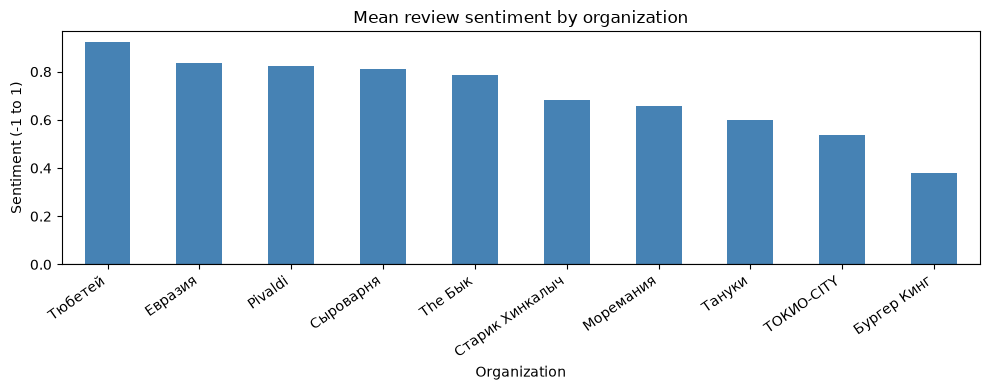

In [3]:
# Результаты сохраняются: при повторном запуске с той же выборкой RuBERT не нужен.
sentiment_columns = ['sentiment_label', 'sentiment', 'confidence']
input_hash = pd.util.hash_pandas_object(
    df[['brand', 'review']], index=False
).values.tobytes()
cache_key = hashlib.sha256(
    f'{MODEL_NAME}|{MAX_LENGTH}|'.encode('utf-8') + input_hash
).hexdigest()[:16]
cache_file = CACHE_DIR / f'sentiment_{cache_key}.parquet'

if cache_file.exists():
    cached = pd.read_parquet(cache_file)
    for column in sentiment_columns:
        df[column] = cached[column].to_numpy()
    print(f'Тональность загружена из кэша: {cache_file}')
else:
    device = 0 if torch.cuda.is_available() else -1
    print('Устройство:', 'GPU' if device == 0 else 'CPU')

    sentiment_model = pipeline(
        'sentiment-analysis',
        model=MODEL_NAME,
        tokenizer=MODEL_NAME,
        device=device
    )
    sentiment_results = sentiment_model(
        df['review'].tolist(),
        batch_size=32 if device == 0 else 8,
        truncation=True,
        max_length=MAX_LENGTH
    )

    def normalize_sentiment(result):
        label = result['label'].upper()
        confidence = float(result['score'])
        if 'POS' in label:
            return 'положительный', confidence, confidence
        if 'NEG' in label:
            return 'отрицательный', -confidence, confidence
        return 'нейтральный', 0.0, confidence

    df[sentiment_columns] = pd.DataFrame(
        [normalize_sentiment(result) for result in sentiment_results],
        index=df.index,
        columns=sentiment_columns
    )
    CACHE_DIR.mkdir(exist_ok=True)
    df[sentiment_columns].to_parquet(cache_file, index=False)
    print(f'Результат сохранён в кэш: {cache_file}')

brand_summary = (df.groupby('brand')
    .agg(
        reviews_count=('review', 'size'),
        mean_sentiment=('sentiment', 'mean'),
        median_sentiment=('sentiment', 'median'),
        positive_share=('sentiment_label', lambda labels: labels.eq('положительный').mean()),
        neutral_share=('sentiment_label', lambda labels: labels.eq('нейтральный').mean()),
        negative_share=('sentiment_label', lambda labels: labels.eq('отрицательный').mean()),
    )
    .sort_values('mean_sentiment', ascending=False))

display(brand_summary.style.format({
    'mean_sentiment': '{:.3f}', 'median_sentiment': '{:.3f}',
    'positive_share': '{:.1%}', 'neutral_share': '{:.1%}', 'negative_share': '{:.1%}'
}))

brand_summary['mean_sentiment'].plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.title('Mean review sentiment by organization')
plt.ylabel('Sentiment (-1 to 1)')
plt.xlabel('Organization')
plt.xticks(rotation=35, ha='right')
plt.axhline(0, color='black', lw=.8)
plt.tight_layout()
plt.show()


## 2. Тональность по атрибутам: цена, качество, сервис
Отзыв может относиться сразу к нескольким атрибутам. Ключевые слова служат простым фильтром; перед выводами проверьте словари и примеры найденных отзывов.

,brand,aspect,reviews_count,mean_sentiment,median_sentiment
27,Тюбетей,качество,188,0.927148,0.981189
18,Сыроварня,качество,180,0.875911,0.981137
9,Евразия,качество,221,0.870086,0.981270
0,Pivaldi,качество,184,0.864322,0.981078
3,The Бык,качество,197,0.828116,0.980897
15,Старик Хинкалыч,качество,226,0.757093,0.980839
12,Моремания,качество,163,0.749678,0.980498
24,Тануки,качество,206,0.698341,0.980775
21,ТОКИО-CITY,качество,176,0.616768,0.980274
6,Бургер Кинг,качество,162,0.567608,0.976148


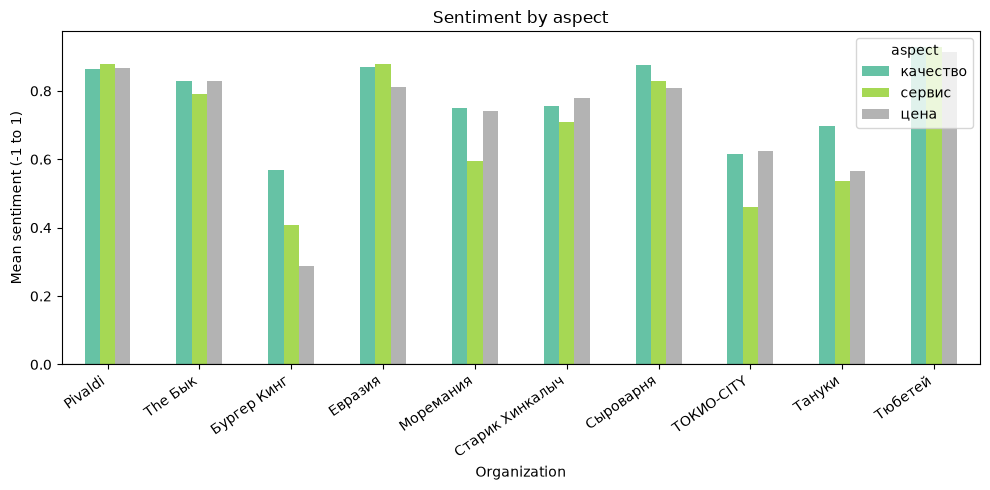

In [4]:
def detect_aspects(text):
    text = str(text).lower()
    return [aspect for aspect, words in ASPECT_KEYWORDS.items()
            if any(word in text for word in words)]

df['aspects'] = df['review'].apply(detect_aspects)
aspect_df = df.explode('aspects').dropna(subset=['aspects']).rename(columns={'aspects': 'aspect'})
if aspect_df.empty:
    raise ValueError('No reviews matched the aspect keywords. Check ASPECT_KEYWORDS.')
aspect_summary = (aspect_df.groupby(['brand', 'aspect'])
    .agg(
        reviews_count=('sentiment', 'size'),
        mean_sentiment=('sentiment', 'mean'),
        median_sentiment=('sentiment', 'median'),
    )
    .reset_index())
display(aspect_summary.sort_values(['aspect', 'mean_sentiment'], ascending=[True, False]))

aspect_pivot = aspect_summary.pivot(index='brand', columns='aspect', values='mean_sentiment')
aspect_pivot.plot(kind='bar', figsize=(10, 5), colormap='Set2')
plt.title('Sentiment by aspect'); plt.ylabel('Mean sentiment (-1 to 1)')
plt.xlabel('Organization'); plt.xticks(rotation=35, ha='right'); plt.axhline(0, color='black', lw=.8)
plt.tight_layout(); plt.show()


## 3. SWOT выбранной организации
Сильные/слабые стороны определяются по абсолютной тональности атрибута; возможности/угрозы — по разнице со средним уровнем конкурентов. Это выводы из отзывов, а не финансовая оценка компании.

In [5]:
if TARGET_BRAND not in df['brand'].unique():
    raise ValueError(f'Бренд {TARGET_BRAND!r} отсутствует. Доступны: {sorted(df.brand.unique())}')

swot = {'Сильные стороны': [], 'Слабые стороны': [], 'Возможности': [], 'Угрозы': []}
target_scores = aspect_summary[aspect_summary.brand == TARGET_BRAND].set_index('aspect')['mean_sentiment']
competitor_scores = aspect_summary[aspect_summary.brand != TARGET_BRAND].groupby('aspect')['mean_sentiment'].mean()
for aspect, score in target_scores.items():
    if score >= 0.15:
        swot['Сильные стороны'].append(f'{aspect.capitalize()}: положительная оценка ({score:.2f})')
    elif score <= -0.15:
        swot['Слабые стороны'].append(f'{aspect.capitalize()}: отрицательная оценка ({score:.2f})')
    if aspect in competitor_scores.index:
        gap = competitor_scores[aspect] - score
        if gap >= 0.15:
            swot['Возможности'].append(f'{aspect.capitalize()}: улучшить; среднее конкурентов выше на {gap:.2f}')
        elif gap <= -0.15:
            swot['Угрозы'].append(f'{aspect.capitalize()}: сохранить преимущество; отрыв от конкурентов {abs(gap):.2f}')

for section, items in swot.items():
    print(f'\n{section}')
    print('\n'.join(f'• {item}' for item in items) if items else '• Недостаточно данных для вывода')


Сильные стороны
• Качество: положительная оценка (0.57)
• Сервис: положительная оценка (0.41)
• Цена: положительная оценка (0.29)

Слабые стороны
• Недостаточно данных для вывода

Возможности
• Качество: улучшить; среднее конкурентов выше на 0.23
• Сервис: улучшить; среднее конкурентов выше на 0.33
• Цена: улучшить; среднее конкурентов выше на 0.48

Угрозы
• Недостаточно данных для вывода


## 4. Карта восприятия организаций (MDS)
Расстояние между организациями одной рубрики рассчитывается по профилям тональности в трёх атрибутах. Оси MDS не имеют самостоятельного смысла: интерпретируйте относительную близость организаций.

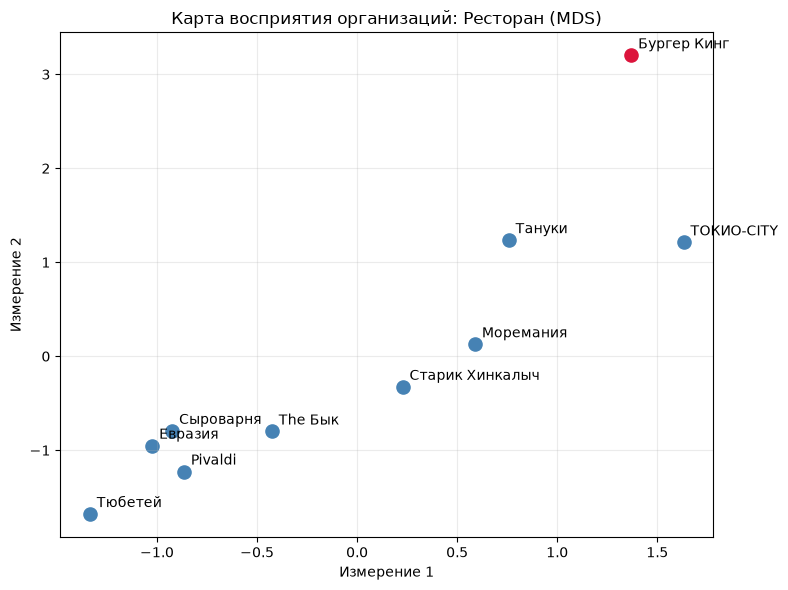

,mds_1,mds_2
brand,,
Pivaldi,-0.865045,-1.226861
The Бык,-0.426184,-0.800811
Бургер Кинг,1.369590,3.202373
Евразия,-1.023638,-0.951033
Моремания,0.588987,0.127099
Старик Хинкалыч,0.227205,-0.325613
Сыроварня,-0.923981,-0.794141
ТОКИО-CITY,1.631019,1.212222
Тануки,0.757287,1.235704


In [6]:
profile = aspect_summary.pivot(index='brand', columns='aspect', values='mean_sentiment')
profile = profile.reindex(columns=list(ASPECT_KEYWORDS)).fillna(0)
if len(profile) < 2:
    raise ValueError('Для MDS нужно не менее двух организаций; увеличьте MAX_BRANDS или снизьте MIN_REVIEWS.')
# Стандартизация делает атрибуты сопоставимыми при расчёте расстояний.
scaled = StandardScaler().fit_transform(profile)
distances = pairwise_distances(scaled, metric='euclidean')
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42, n_init=4, max_iter=500)
coords = mds.fit_transform(distances)

plt.figure(figsize=(8, 6))
for i, brand in enumerate(profile.index):
    color = 'crimson' if brand == TARGET_BRAND else 'steelblue'
    plt.scatter(coords[i, 0], coords[i, 1], s=90, color=color)
    plt.annotate(brand, (coords[i, 0], coords[i, 1]), xytext=(5, 5), textcoords='offset points')
plt.title(f'Карта восприятия организаций: {TARGET_RUBRIC} (MDS)'); plt.xlabel('Измерение 1'); plt.ylabel('Измерение 2')
plt.grid(alpha=.25); plt.tight_layout(); plt.show()

coordinates = pd.DataFrame(coords, index=profile.index, columns=['mds_1', 'mds_2'])
display(coordinates)

## 5.анализ
### 5.1 Профиль оценок (звёзды) и расхождение с тональностью
Распределение оценок 1–5 по сетям и сопоставление места по среднему рейтингу с местом по тональности текста: расхождение показывает, где формальные звёзды и реальное содержание отзывов расходятся.

rating,1,2,3,4,5,mean_rating,median_rating
brand,,,,,,,
Тюбетей,0.8,0.0,0.4,6.2,92.5,4.90,5.0
Pivaldi,2.0,1.2,5.5,11.3,80.1,4.66,5.0
Евразия,5.3,0.7,4.0,4.0,86.0,4.65,5.0
Сыроварня,3.2,3.2,5.9,9.9,77.9,4.56,5.0
The Бык,4.7,2.5,6.1,12.2,74.6,4.49,5.0
Старик Хинкалыч,10.3,3.7,4.0,11.0,71.0,4.29,5.0
Моремания,7.9,4.8,6.1,12.7,68.6,4.27,5.0
Тануки,13.7,3.7,9.0,14.3,59.3,4.02,5.0
ТОКИО-CITY,15.7,5.0,10.3,11.0,58.0,3.91,5.0


,mean_rating,rank_by_mean_rating,median_rating,rank_by_median_rating,mean_sentiment,rank_by_mean_sentiment,median_sentiment,rank_by_median_sentiment,rank_gap_mean,rank_gap_median
brand,,,,,,,,,,
Тюбетей,4.90,1,5.0,5,0.921,1,0.981,2,0,3
Евразия,4.65,3,5.0,5,0.836,2,0.981,1,1,4
Pivaldi,4.66,2,5.0,5,0.823,3,0.981,3,-1,2
Сыроварня,4.56,4,5.0,5,0.811,4,0.981,4,0,1
The Бык,4.49,5,5.0,5,0.787,5,0.981,6,0,-1
Старик Хинкалыч,4.29,6,5.0,5,0.684,6,0.981,5,0,0
Моремания,4.27,7,5.0,5,0.660,7,0.980,8,0,-3
Тануки,4.02,8,5.0,5,0.601,8,0.980,7,0,-2
ТОКИО-CITY,3.91,9,5.0,5,0.537,9,0.978,9,0,-4


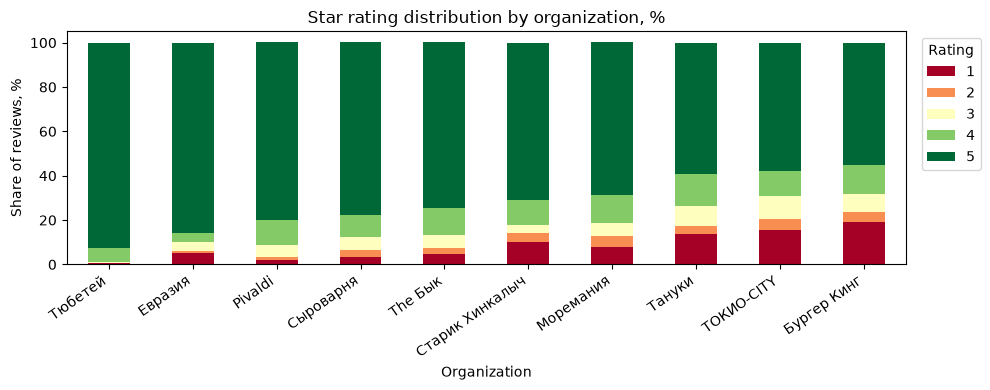

In [7]:
rating_counts = pd.crosstab(df['brand'], df['rating']).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
rating_share = (rating_counts.div(rating_counts.sum(axis=1), axis=0) * 100).round(1)
mean_rating = df.groupby('brand')['rating'].mean().round(2)
median_rating = df.groupby('brand')['rating'].median().round(2)
rating_profile = rating_share.copy()
rating_profile['mean_rating'] = mean_rating
rating_profile['median_rating'] = median_rating
display(rating_profile.sort_values('mean_rating', ascending=False))

mean_rating_rank = mean_rating.rank(ascending=False).astype(int)
median_rating_rank = median_rating.rank(ascending=False).astype(int)
mean_sentiment = brand_summary['mean_sentiment']
median_sentiment = brand_summary['median_sentiment']
mean_sentiment_rank = mean_sentiment.rank(ascending=False).astype(int)
median_sentiment_rank = median_sentiment.rank(ascending=False).astype(int)
rank_divergence = pd.DataFrame({
    'mean_rating': mean_rating,
    'rank_by_mean_rating': mean_rating_rank,
    'median_rating': median_rating,
    'rank_by_median_rating': median_rating_rank,
    'mean_sentiment': mean_sentiment.round(3),
    'rank_by_mean_sentiment': mean_sentiment_rank,
    'median_sentiment': median_sentiment.round(3),
    'rank_by_median_sentiment': median_sentiment_rank,
})
rank_divergence['rank_gap_mean'] = mean_rating_rank - mean_sentiment_rank
rank_divergence['rank_gap_median'] = median_rating_rank - median_sentiment_rank
display(rank_divergence.sort_values('rank_by_mean_sentiment'))

rating_share.loc[brand_summary.index].plot(kind='bar', stacked=True, figsize=(10, 4), colormap='RdYlGn')
plt.title('Star rating distribution by organization, %')
plt.ylabel('Share of reviews, %'); plt.xlabel('Organization')
plt.xticks(rotation=35, ha='right'); plt.legend(title='Rating', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()


### 5.2 Структура тональности
Доли положительных, нейтральных и отрицательных отзывов по каждой сети. Доля негатива — более чувствительный показатель риска, чем средняя тональность.

sentiment_label,положительный,нейтральный,отрицательный
brand,,,
Тюбетей,96.7,1.2,2.1
Евразия,90.0,4.7,5.3
Pivaldi,90.6,3.1,6.2
Сыроварня,88.5,5.5,5.9
The Бык,88.5,4.3,7.2
Старик Хинкалыч,80.7,7.0,12.3
Моремания,79.1,7.4,13.5
Тануки,75.3,8.7,16.0
ТОКИО-CITY,71.3,9.3,19.3


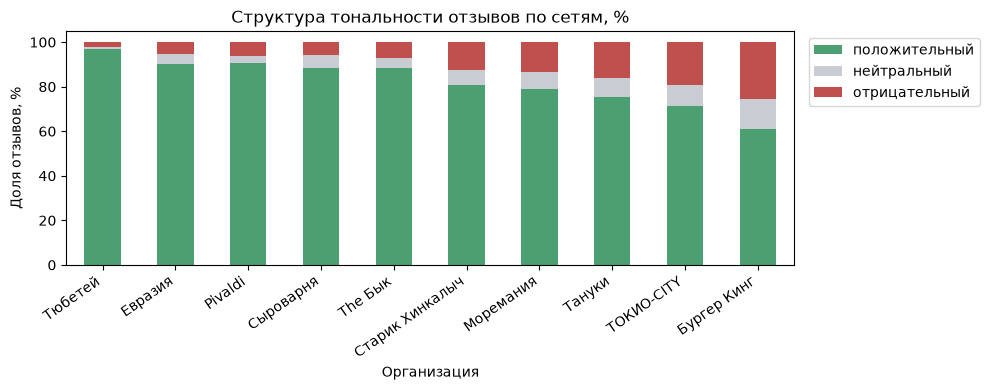

In [8]:
sent_profile = (pd.crosstab(df['brand'], df['sentiment_label'], normalize='index') * 100).round(1)
sent_profile = sent_profile.reindex(columns=['положительный', 'нейтральный', 'отрицательный'], fill_value=0)
display(sent_profile.loc[brand_summary.index])

sent_profile.loc[brand_summary.index].plot(
    kind='bar', stacked=True, figsize=(10, 4), color=['#4C9F70', '#C9CDD3', '#C0504D'])
plt.title('Структура тональности отзывов по сетям, %')
plt.ylabel('Доля отзывов, %'); plt.xlabel('Организация')
plt.xticks(rotation=35, ha='right'); plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

### 5.3 О чём пишут: доля тем в отзывах сети
Доля отзывов каждой сети, затрагивающих цену, качество и сервис. Показывает, какие темы формируют образ сети: у одной сети обсуждают еду, у другой — обслуживание.

aspect,качество,сервис,цена
brand,,,
Тюбетей,78.3,41.7,24.6
Евразия,73.7,59.7,23.3
Pivaldi,71.9,51.2,45.7
Сыроварня,71.1,62.8,22.1
The Бык,70.6,46.2,49.1
Старик Хинкалыч,75.3,52.7,35.0
Моремания,70.9,53.9,37.0
Тануки,68.7,64.0,22.0
ТОКИО-CITY,58.7,58.0,33.0


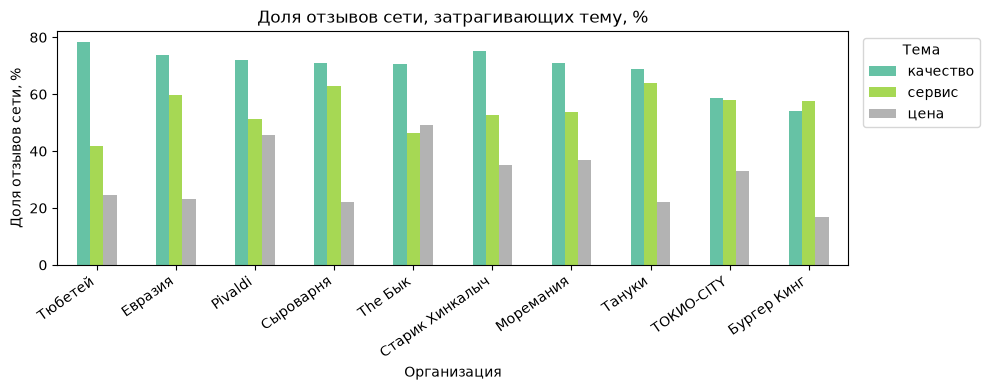

In [9]:
aspect_df_clean = aspect_df.reset_index(drop=True)
mentions = pd.crosstab(aspect_df_clean['brand'], aspect_df_clean['aspect'])
aspect_share = (mentions.div(df['brand'].value_counts(), axis=0) * 100).round(1)
display(aspect_share.loc[brand_summary.index])

aspect_share.loc[brand_summary.index].plot(kind='bar', figsize=(10, 4), colormap='Set2')
plt.title('Доля отзывов сети, затрагивающих тему, %')
plt.ylabel('Доля отзывов сети, %'); plt.xlabel('Организация')
plt.xticks(rotation=35, ha='right'); plt.legend(title='Тема', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

### 5.4 Длина отзыва и тональность
Проверка гипотезы: недовольные клиенты пишут подробнее. Отрицательная корреляция длины с тональностью подтверждает, что негативные отзывы развёрнутее — их стоит читать в первую очередь.

,mean,median,size
sentiment_label,,,
нейтральный,355.0,254.0,183
отрицательный,427.0,313.0,323
положительный,251.0,190.0,2252


Корреляция длины отзыва и тональности: -0.242


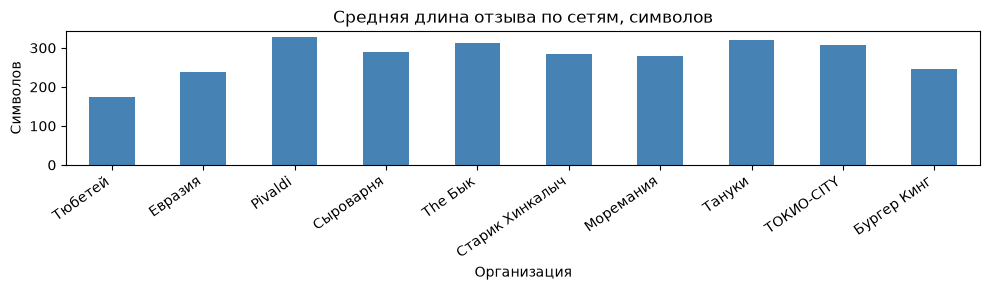

In [10]:
df['review_len'] = df['review'].str.len()
len_by_class = df.groupby('sentiment_label')['review_len'].agg(['mean', 'median', 'size']).round(0)
display(len_by_class)
print(f"Корреляция длины отзыва и тональности: {df['review_len'].corr(df['sentiment']):.3f}")

len_by_brand = df.groupby('brand')['review_len'].mean().round(0).loc[brand_summary.index]
len_by_brand.plot(kind='bar', figsize=(10, 3), color='steelblue')
plt.title('Средняя длина отзыва по сетям, символов')
plt.ylabel('Символов'); plt.xlabel('Организация')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

### 5.5 Итоговый scorecard
Все ключевые метрики в одной таблице: объём выборки, звёзды, тональность, доля позитива и негатива, оценки по трём атрибутам и итоговое место.

In [11]:
aspect_sent = aspect_summary.pivot(index='brand', columns='aspect', values='mean_sentiment').round(2)
scorecard = pd.DataFrame({
    'reviews': df['brand'].value_counts(),
    'mean_rating': mean_rating,
    'median_rating': median_rating,
    'mean_sentiment': brand_summary['mean_sentiment'].round(3),
    'median_sentiment': brand_summary['median_sentiment'].round(3),
    'positive_%': sent_profile['\u043f\u043e\u043b\u043e\u0436\u0438\u0442\u0435\u043b\u044c\u043d\u044b\u0439'],
    'neutral_%': sent_profile['\u043d\u0435\u0439\u0442\u0440\u0430\u043b\u044c\u043d\u044b\u0439'],
    'negative_%': sent_profile['\u043e\u0442\u0440\u0438\u0446\u0430\u0442\u0435\u043b\u044c\u043d\u044b\u0439'],
}).join(aspect_sent).sort_values('mean_sentiment', ascending=False)
scorecard['rank'] = range(1, len(scorecard) + 1)
display(scorecard.style.format({
    'mean_rating': '{:.2f}', 'median_rating': '{:.2f}',
    'mean_sentiment': '{:.3f}', 'median_sentiment': '{:.3f}',
    'positive_%': '{:.1f}', 'neutral_%': '{:.1f}', 'negative_%': '{:.1f}'
}))


,reviews,mean_rating,median_rating,mean_sentiment,median_sentiment,positive_%,neutral_%,negative_%,качество,сервис,цена,rank
brand,,,,,,,,,,,,
Тюбетей,240,4.90,5.00,0.921,0.981,96.7,1.2,2.1,0.930000,0.930000,0.920000,1
Евразия,300,4.65,5.00,0.836,0.981,90.0,4.7,5.3,0.870000,0.880000,0.810000,2
Pivaldi,256,4.66,5.00,0.823,0.981,90.6,3.1,6.2,0.860000,0.880000,0.870000,3
Сыроварня,253,4.56,5.00,0.811,0.981,88.5,5.5,5.9,0.880000,0.830000,0.810000,4
The Бык,279,4.49,5.00,0.787,0.981,88.5,4.3,7.2,0.830000,0.790000,0.830000,5
Старик Хинкалыч,300,4.29,5.00,0.684,0.981,80.7,7.0,12.3,0.760000,0.710000,0.780000,6
Моремания,230,4.27,5.00,0.660,0.980,79.1,7.4,13.5,0.750000,0.600000,0.740000,7
Тануки,300,4.02,5.00,0.601,0.980,75.3,8.7,16.0,0.700000,0.540000,0.570000,8
ТОКИО-CITY,300,3.91,5.00,0.537,0.978,71.3,9.3,19.3,0.620000,0.460000,0.620000,9


### 5.6 География целевой сети
Тональность отзывов целевой организации по регионам (из адреса точки). Помогает отличить системную проблему сети от проблем отдельных городов. Показаны регионы с 10+ отзывами.

,review_count,mean_sentiment,median_sentiment,mean_rating,median_rating
region,,,,,
Московская область,50,0.49,0.98,3.74,5.0
Свердловская область,14,0.45,0.95,3.93,4.5
Москва,73,0.30,0.92,3.53,4.0
Санкт-Петербург,38,0.24,0.30,3.71,5.0
Республика Татарстан,13,0.21,0.00,3.85,5.0


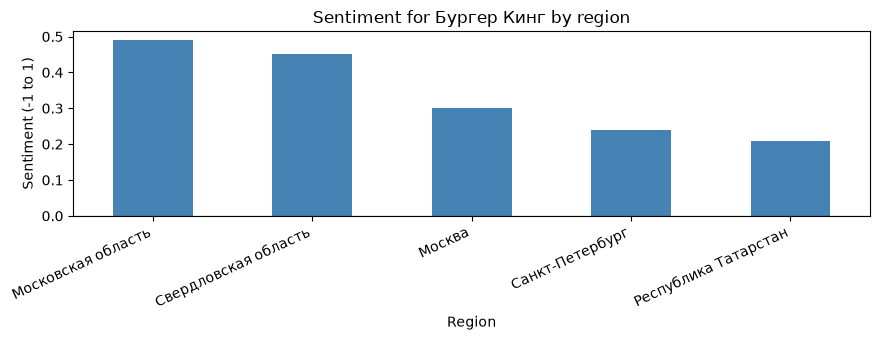

In [12]:
target_reviews = df[df['brand'] == TARGET_BRAND].copy()
target_reviews['region'] = target_reviews['address'].astype(str).str.split(',').str[0].str.strip()
geo_summary = (target_reviews.groupby('region')
    .agg(
        review_count=('sentiment', 'size'),
        mean_sentiment=('sentiment', 'mean'),
        median_sentiment=('sentiment', 'median'),
        mean_rating=('rating', 'mean'),
        median_rating=('rating', 'median'),
    )
    .round(2))
geo_summary = geo_summary[geo_summary['review_count'] >= 10].sort_values('mean_sentiment', ascending=False)
display(geo_summary)

geo_summary['mean_sentiment'].plot(kind='bar', figsize=(9, 3.5), color='steelblue')
plt.title(f'Sentiment for {TARGET_BRAND} by region')
plt.ylabel('Sentiment (-1 to 1)'); plt.xlabel('Region')
plt.xticks(rotation=25, ha='right'); plt.axhline(0, color='black', lw=.8)
plt.tight_layout(); plt.show()


### 5.7 Примеры отзывов целевой сети
Самые положительные и самые отрицательные отзывы по оценке модели. Чтение крайних примеров — обязательная проверка перед выводами по числовым таблицам.

In [13]:
top_positive = target_reviews.nlargest(3, 'sentiment')[['sentiment', 'rating', 'review']]
top_negative = target_reviews.nsmallest(3, 'sentiment')[['sentiment', 'rating', 'review']]
for label, sample in [('Самые положительные', top_positive), ('Самые отрицательные', top_negative)]:
    print(f'\n{label}:')
    for _, row in sample.iterrows():
        text = ' '.join(str(row['review']).split())[:250]
        print(f"[{row['sentiment']:+.2f} | {row['rating']}★] {text}\n")


Самые положительные:
[+0.99 | 5★] Что можно написать про сеть БК? Молодцы, вкусно! И всегда что-то придумывают. Сейчас стартануло острое меню, отлично просто!)) Для "остроежек" типо меня-рай!

[+0.99 | 5★] БК хорошее место, не поддерживаю максимально мемы с тик тока, крутой сервис, крутые ребята, все быстро готовят, заказы за триллион раз не перепутали)))

[+0.99 | 5★] Да замечательно, как и всегда). В любой стране и любом городе Бургер Кинг это он и есть, что и приятно.


Самые отрицательные:
[-0.99 | 4★] Бываю редко, неуютно теперь.\nМеню как и раньше, только водичка не вкусная (

[-0.99 | 1★] Надо бросать есть эту гадость из бургер Кинга , бургеры и картошка отказываются перевариваться ((( это настолько неестественная еда что организм отторгает и не переваривает этот противоестественный ужас ! Никому не рекомендую

[-0.99 | 3★] Все хорошо, персонал норм. Но тут часто бывают гопники (как они себя называют "БКашники". А в целом норм



## 6. Выводы и рекомендации по ребрендингу
Используйте полученные таблицы для формулировки рекомендаций: закрепить сильные атрибуты в коммуникации, устранить причины низких оценок, проверить отставание от конкурентов и уточнить позиционирование по карте MDS. Учитывайте число отзывов: при малой выборке выводы ненадёжны.

In [14]:
# Экспорт таблиц, чтобы использовать их при подготовке отчёта.
brand_summary.to_csv('brand_summary.csv', encoding='utf-8-sig')
aspect_summary.to_csv('aspect_summary.csv', index=False, encoding='utf-8-sig')
coordinates.to_csv('perception_map.csv', encoding='utf-8-sig')
df.to_csv('reviews_scored.csv', index=False, encoding='utf-8-sig')

# Таблицы дополнительного анализа (раздел 5).
rating_profile.to_csv('rating_profile.csv', encoding='utf-8-sig')
rank_divergence.to_csv('rank_divergence.csv', encoding='utf-8-sig')
sent_profile.to_csv('sentiment_profile.csv', encoding='utf-8-sig')
aspect_share.to_csv('aspect_share.csv', encoding='utf-8-sig')
len_by_class.to_csv('length_by_sentiment.csv', encoding='utf-8-sig')
scorecard.to_csv('scorecard.csv', encoding='utf-8-sig')
geo_summary.to_csv('geo_summary.csv', encoding='utf-8-sig')
print('Сохранены 11 CSV: brand_summary, aspect_summary, perception_map, reviews_scored, rating_profile, rank_divergence, sentiment_profile, aspect_share, length_by_sentiment, scorecard, geo_summary')

Сохранены 11 CSV: brand_summary, aspect_summary, perception_map, reviews_scored, rating_profile, rank_divergence, sentiment_profile, aspect_share, length_by_sentiment, scorecard, geo_summary
